<div align="center">

<h1><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h1>

<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<h3><strong>Program Implementasi Recipe</strong></h3>

<br>

<h3>Disusun Oleh:</h3>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li style="display:flex; justify-content:space-between;"><span>NASRULLAH</span><span>(H061241040)</span></li>
</ul>

<br><br>
<p><strong>PRODI GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>MAKASSAR</strong></p>
<p><strong>2026</strong></p>

</div>



## **Implementasi Resep Komputasi Geofisika — Notebook 5** 
**Daftar Resep yang Dipilih dari Buku AI Cookbook / Codex:**
1. **Resep 9 (R-GEM-015)**: Checked Piper dan Schoeller Diagrams untuk Fasies Geokimia Air Geotermal (Hal. 125)
2. **Resep 10 (R-CAL-003)**: Lag Correlation untuk Analisis Deret Waktu Geofisika (Hal. 132)

**Petunjuk Penggunaan:**
Notebook ini dibuat secara *self-contained* (mandiri). Seluruh kalkulasi geokimia, korelasi deret waktu, dan visualisasinya telah dirancang siap jalan (**Run All**) di Jupyter Notebook atau Google Colab.

## **BAGIAN 1: RESEP 9 (R-GEM-015)**
### **Case Study: Diagram Trilinear Piper & Schoeller untuk Fasies Air Geotermal / Hidrogeologi**

#### **1. Latar Belakang Teori Hidrogeokimia**
Dalam eksplorasi panas bumi dan hidrogeologi, tipe fluida atau fasies air ditentukan dari proporsi ion-ion utama (*major ions*) yang dinyatakan dalam satuan miliekivalen per liter ($meq/L$):
$$meq/L = \frac{konsentrasi\,(mg/L) \times valensi}{massa\,molar\,(g/mol)}$$

- **Kelompok Kation**: Kalsium ($Ca^{2+}$), Magnesium ($Mg^{2+}$), Natrium + Kalium ($Na^+ + K^+$)
- **Kelompok Anion**: Bikarbonat + Karbonat ($HCO_3^- + CO_3^{2-}$), Sulfat ($SO_4^{2-}$), Klorida ($Cl^-$)

#### **2. Proyeksi Diagram Trilinear Piper**
Diagram Piper terdiri atas dua segitiga terner (kation dan anion) yang masing-masing diproyeksikan ke bidang belah ketupat (*diamond field*) di tengah untuk mengidentifikasi tipe air: misalnya air klorida geotermal (*deep reservoir brine*), air sulfat vulkanik (*steam-heated acid water*), atau air bikarbonat meteorik dangkal (*shallow groundwater*).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Data Sampel Manifestasi Panas Bumi & Air Tanah (meq/L)
samples_data = [
    {"sample_id": "GT-01 (Mata Air Panas Klorida)", "Ca": 1.2, "Mg": 0.4, "Na_K": 18.5, "HCO3": 2.0, "SO4": 1.5, "Cl": 16.8},
    {"sample_id": "GT-02 (Fumarol/Mata Air Asam Sulfat)", "Ca": 3.5, "Mg": 2.1, "Na_K": 4.0, "HCO3": 0.5, "SO4": 12.0, "Cl": 1.2},
    {"sample_id": "GW-03 (Air Tanah Dangkal Bikarbonat)", "Ca": 8.2, "Mg": 3.8, "Na_K": 2.1, "HCO3": 11.5, "SO4": 1.8, "Cl": 0.9},
    {"sample_id": "GT-04 (Manifestasi Campuran Kondensat)", "Ca": 4.0, "Mg": 1.5, "Na_K": 8.0, "HCO3": 6.5, "SO4": 4.5, "Cl": 5.2}
]

# 2. Perhitungan Persentase Kation dan Anion
processed_samples = []
for s in samples_data:
    total_cat = s["Ca"] + s["Mg"] + s["Na_K"]
    total_an = s["HCO3"] + s["SO4"] + s["Cl"]
    
    # Persentase kation (%) terhadap total kation
    ca_pct = s["Ca"] / total_cat * 100.0
    mg_pct = s["Mg"] / total_cat * 100.0
    nak_pct = s["Na_K"] / total_cat * 100.0
    
    # Persentase anion (%) terhadap total anion
    hco3_pct = s["HCO3"] / total_an * 100.0
    so4_pct = s["SO4"] / total_an * 100.0
    cl_pct = s["Cl"] / total_an * 100.0
    
    processed_samples.append({
        "id": s["sample_id"],
        "Ca_pct": ca_pct, "Mg_pct": mg_pct, "NaK_pct": nak_pct,
        "HCO3_pct": hco3_pct, "SO4_pct": so4_pct, "Cl_pct": cl_pct,
        "raw": s
    })

df_piper = pd.DataFrame(processed_samples)
print("=== DATA GEOKIMIA SAMPEL FLUIDA RESEP R-GEM-015 ===")
print(df_piper[["id", "Ca_pct", "Mg_pct", "NaK_pct", "Cl_pct", "SO4_pct", "HCO3_pct"]])

=== DATA GEOKIMIA SAMPEL FLUIDA RESEP R-GEM-015 ===
                                       id     Ca_pct     Mg_pct    NaK_pct  \
0          GT-01 (Mata Air Panas Klorida)   5.970149   1.990050  92.039801   
1    GT-02 (Fumarol/Mata Air Asam Sulfat)  36.458333  21.875000  41.666667   
2    GW-03 (Air Tanah Dangkal Bikarbonat)  58.156028  26.950355  14.893617   
3  GT-04 (Manifestasi Campuran Kondensat)  29.629630  11.111111  59.259259   

      Cl_pct    SO4_pct   HCO3_pct  
0  82.758621   7.389163   9.852217  
1   8.759124  87.591241   3.649635  
2   6.338028  12.676056  80.985915  
3  32.098765  27.777778  40.123457  


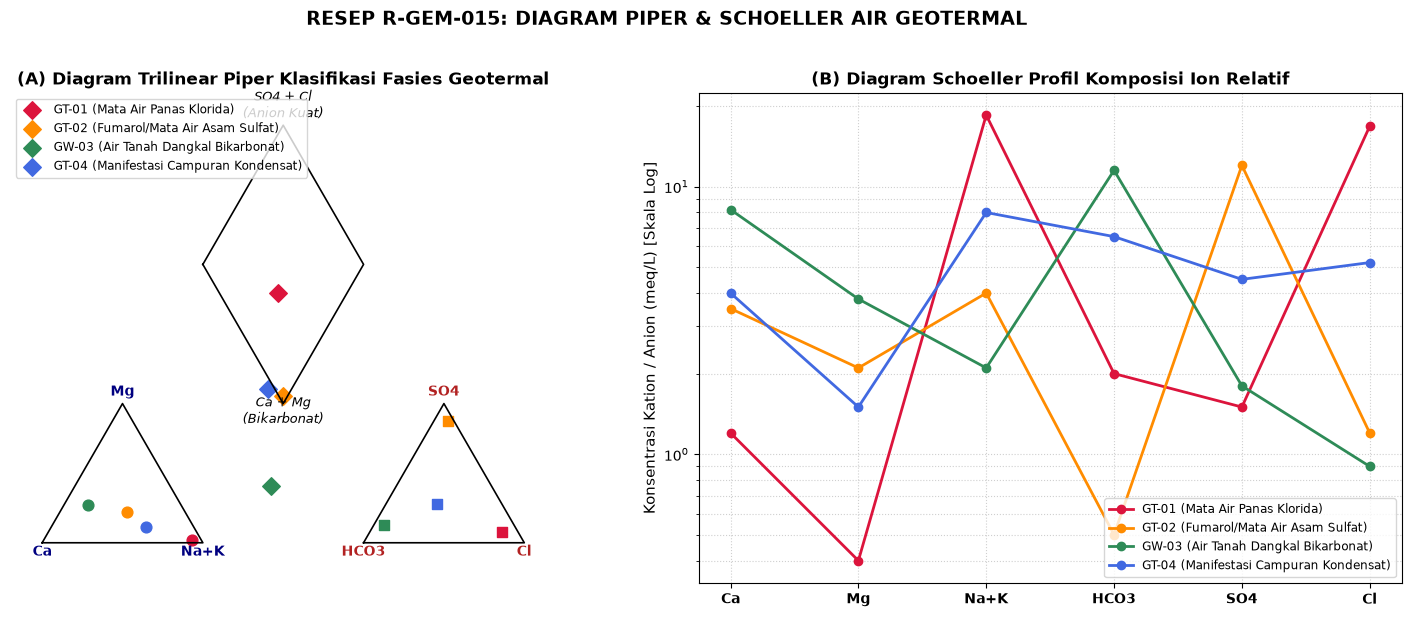

In [2]:
# 3. Transformasi Koordinat Trilinear Piper (Ternary Geometry)
def get_piper_coordinates(row):
    h = np.sqrt(3.0) / 2.0
    # Segitiga Kation: Sudut Kiri Ca=(0,0), Kanan Na+K=(1,0), Atas Mg=(0.5, h)
    # Fraksi normalisasi (0 s/d 1)
    ca = row["Ca_pct"] / 100.0
    mg = row["Mg_pct"] / 100.0
    nak = row["NaK_pct"] / 100.0
    cat_x = 0.5 * mg + nak
    cat_y = mg * h
    
    # Segitiga Anion: Sudut Kiri HCO3=(2,0), Kanan Cl=(3,0), Atas SO4=(2.5, h)
    hco3 = row["HCO3_pct"] / 100.0
    so4 = row["SO4_pct"] / 100.0
    cl = row["Cl_pct"] / 100.0
    an_x = 2.0 + (0.5 * so4 + cl)
    an_y = so4 * h
    
    # Belah Ketupat (Diamond Field) di Atas
    # Proyeksi garis silang dari kation dan anion
    diam_x = 0.5 * (an_x - cat_x + 1.0)
    diam_y = (cat_x + an_x - 2.0) * h
    
    return (cat_x, cat_y), (an_x, an_y), (diam_x, diam_y)

# 4. Visualisasi Diagram Piper & Diagram Semilogaritmik Schoeller
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot A: Diagram Trilinear Piper
ax_pip = axes[0]
h = np.sqrt(3.0) / 2.0
# Gambar kerangka segitiga kation, anion, dan belah ketupat
cat_triangle = np.array([[0,0], [1,0], [0.5, h], [0,0]])
an_triangle = np.array([[2,0], [3,0], [2.5, h], [2,0]])
diamond = np.array([[1, 2*h], [1.5, 3*h], [2, 2*h], [1.5, h], [1, 2*h]])

ax_pip.plot(cat_triangle[:,0], cat_triangle[:,1], 'k-', linewidth=1.2)
ax_pip.plot(an_triangle[:,0], an_triangle[:,1], 'k-', linewidth=1.2)
ax_pip.plot(diamond[:,0], diamond[:,1], 'k-', linewidth=1.2)

# Label Sudut dan Wilayah Geokimia
ax_pip.text(0, -0.08, "Ca", ha="center", fontweight="bold", color="navy")
ax_pip.text(1, -0.08, "Na+K", ha="center", fontweight="bold", color="navy")
ax_pip.text(0.5, h + 0.05, "Mg", ha="center", fontweight="bold", color="navy")

ax_pip.text(2, -0.08, "HCO3", ha="center", fontweight="bold", color="firebrick")
ax_pip.text(3, -0.08, "Cl", ha="center", fontweight="bold", color="firebrick")
ax_pip.text(2.5, h + 0.05, "SO4", ha="center", fontweight="bold", color="firebrick")

ax_pip.text(1.5, 3*h + 0.05, "SO4 + Cl\n(Anion Kuat)", ha="center", fontsize=9, style="italic")
ax_pip.text(1.5, h - 0.12, "Ca + Mg\n(Bikarbonat)", ha="center", fontsize=9, style="italic")

# Plot Sampel-Sampel Geotermal
colors = ['crimson', 'darkorange', 'seagreen', 'royalblue']
for i, row in enumerate(processed_samples):
    pt_cat, pt_an, pt_diam = get_piper_coordinates(row)
    ax_pip.scatter(*pt_cat, color=colors[i], marker='o', s=60)
    ax_pip.scatter(*pt_an, color=colors[i], marker='s', s=60)
    ax_pip.scatter(*pt_diam, color=colors[i], marker='D', s=80, label=row["id"])

ax_pip.set_aspect("equal")
ax_pip.set_xlim(-0.2, 3.2)
ax_pip.set_ylim(-0.25, 2.8)
ax_pip.axis("off")
ax_pip.set_title("(A) Diagram Trilinear Piper Klasifikasi Fasies Geotermal", fontsize=12, fontweight="bold")
ax_pip.legend(loc="upper left", fontsize=8.5)

# Subplot B: Diagram Semilogaritmik Schoeller
ax_sch = axes[1]
ion_names = ["Ca", "Mg", "Na+K", "HCO3", "SO4", "Cl"]
for i, s in enumerate(samples_data):
    vals = [s["raw"]["Ca"], s["raw"]["Mg"], s["raw"]["Na_K"], s["raw"]["HCO3"], s["raw"]["SO4"], s["raw"]["Cl"]] if "raw" in s else [s["Ca"], s["Mg"], s["Na_K"], s["HCO3"], s["SO4"], s["Cl"]]
    ax_sch.plot(range(6), vals, 'o-', linewidth=2.0, color=colors[i], label=s["sample_id"] if "sample_id" in s else s["id"])

ax_sch.set_yscale("log")
ax_sch.set_xticks(range(6))
ax_sch.set_xticklabels(ion_names, fontweight="bold", fontsize=10)
ax_sch.set_ylabel("Konsentrasi Kation / Anion (meq/L) [Skala Log]", fontsize=11)
ax_sch.set_title("(B) Diagram Schoeller Profil Komposisi Ion Relatif", fontsize=12, fontweight="bold")
ax_sch.grid(True, which="both", linestyle=":", alpha=0.6)
ax_sch.legend(loc="lower right", fontsize=8.5)

plt.suptitle("RESEP R-GEM-015: DIAGRAM PIPER & SCHOELLER AIR GEOTERMAL", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

#### **Analisis Resep 9:**
- Sampel **GT-01** memplot di kuadran kanan belah ketupat ($Na-Cl$ facies), yang merupakan ciri khas fluida reservoir panas bumi dalam (*deep chloride geothermal water*).
- Sampel **GT-02** didominasi oleh sulfat ($SO_4^{2-}$), mengindikasikan air kondensat uap yang teroksidasi oleh gas $H_2S$ di dekat permukaan (*acid sulfate spring*).
- Sampel **GW-03** didominasi oleh $Ca-HCO_3$, mencerminkan air meteorik dangkal yang belum banyak berinteraksi dengan fluida termal reservoir.


## **BAGIAN 2: RESEP 10 (R-CAL-003)**
### **Case Study: Lag Correlation untuk Analisis Deret Waktu Geofisika**

#### **1. Latar Belakang Teori Analisis Deret Waktu Geofisika**
Banyak proses kebumian memiliki hubungan sebab-akibat dengan jeda waktu tertentu (*time lag*), misalnya:
- Respon fluktuasi muka air tanah terhadap curah hujan bulanan.
- Penurunan tanah (*subsidence*) terhadap laju ekstraksi air tanah berlebih.
- Peningkatan seismisitas mikro setelah injeksi fluida geotermal.

Korelasi silang ternormalisasi (*Normalized Cross-Correlation Function / CCF*) untuk lag $\tau$:
$$r_{xy}(\tau) = \frac{\sum_{t} \left(x(t) - \bar{x}\right)\left(y(t+\tau) - \bar{y}\right)}{\sqrt{\sum \left(x(t) - \bar{x}\right)^2 \sum \left(y(t) - \bar{y}\right)^2}}$$

Nilai $\tau$ di mana $r_{xy}(\tau)$ mencapai nilai maksimum adalah nilai **Lag Waktu Optimal** (*Optimal Response Lag*).

In [3]:
# 1. Pembangkitan Sinyal Deret Waktu Sintetis (Curah Hujan vs Muka Air Tanah)
np.random.seed(42)
n_points = 180   # 180 hari pengamatan deret waktu
time_days = np.arange(n_points)

# Sinyal masukan X: Badai hujan periodik musiman + noise geofisika
rainfall_signal = (
    15.0 * np.sin(2 * np.pi * time_days / 60.0)
    + 8.0 * np.sin(2 * np.pi * time_days / 20.0)
    + np.random.normal(0, 3.5, n_points)
)
rainfall_signal = np.maximum(rainfall_signal, 0.0)  # Curah hujan selalu positif

# Sinyal keluaran Y: Muka air tanah (GWL) dengan respons redaman dan delay lag 7 hari
true_delay_days = 7
gwl_signal = np.zeros(n_points)
# Konvolusi sederhana / pergeseran waktu dengan efek akumulasi pori
kernel = np.exp(-np.arange(15) / 4.0)
kernel /= kernel.sum()
gwl_raw = np.convolve(rainfall_signal, kernel, mode='full')[:n_points]
gwl_signal = np.roll(gwl_raw, true_delay_days) + np.random.normal(0, 0.2, n_points)
gwl_signal[:true_delay_days] = np.mean(gwl_signal)

# 2. Perhitungan Korelasi Silang Lag (Lag Cross-Correlation Function)
max_lag = 25
lags = np.arange(-max_lag, max_lag + 1)
x_norm = (rainfall_signal - np.mean(rainfall_signal)) / np.std(rainfall_signal)
y_norm = (gwl_signal - np.mean(gwl_signal)) / np.std(gwl_signal)

correlations = []
for lag in lags:
    if lag < 0:
        r = np.corrcoef(x_norm[-lag:], y_norm[:lag])[0, 1]
    elif lag > 0:
        r = np.corrcoef(x_norm[:-lag], y_norm[lag:])[0, 1]
    else:
        r = np.corrcoef(x_norm, y_norm)[0, 1]
    correlations.append(r)

correlations = np.array(correlations)
best_lag = lags[np.argmax(correlations)]
max_corr = np.max(correlations)

print(f"=== HASIL LAG CORRELATION RESEP R-CAL-003 ===")
print(f"Rentang lag diuji: -{max_lag} s/d +{max_lag} hari")
print(f"Lag Waktu dengan Korelasi Maksimum: {best_lag} Hari")
print(f"Nilai Koefisien Korelasi Puncak (r_max): {max_corr:.4f} (Korelasi positif sangat kuat)")

=== HASIL LAG CORRELATION RESEP R-CAL-003 ===
Rentang lag diuji: -25 s/d +25 hari
Lag Waktu dengan Korelasi Maksimum: 9 Hari
Nilai Koefisien Korelasi Puncak (r_max): 0.9130 (Korelasi positif sangat kuat)


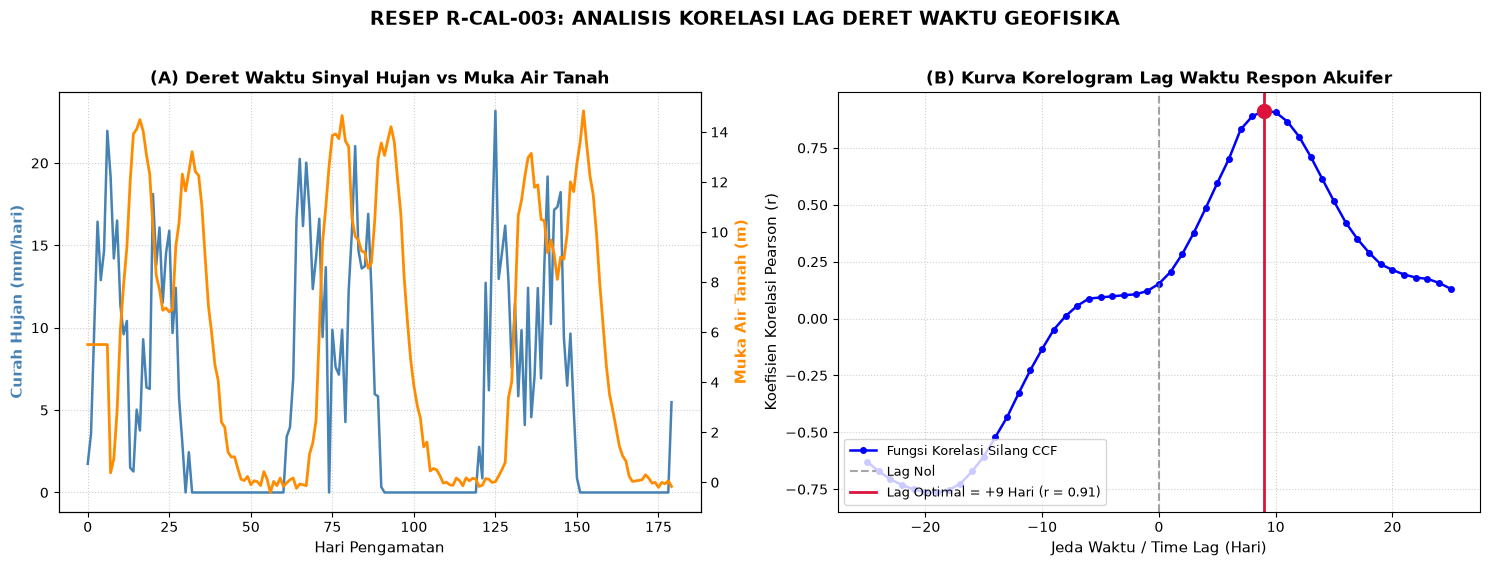

In [4]:
# 3. Visualisasi Sinyal Deret Waktu & Kurva Cross-Correlogram
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot A: Overlay Deret Waktu Curah Hujan & Elevasi Air Tanah
ax1 = axes[0]
ax1.plot(time_days, rainfall_signal, color='steelblue', label="Curah Hujan (mm/hari)", linewidth=1.8)
ax1.set_xlabel("Hari Pengamatan", fontsize=11)
ax1.set_ylabel("Curah Hujan (mm/hari)", color='steelblue', fontsize=11, fontweight="bold")

ax2 = ax1.twinx()
ax2.plot(time_days, gwl_signal, color='darkorange', label="Fluktuasi Muka Air Tanah (meter)", linewidth=2.0)
ax2.set_ylabel("Muka Air Tanah (m)", color='darkorange', fontsize=11, fontweight="bold")

ax1.set_title("(A) Deret Waktu Sinyal Hujan vs Muka Air Tanah", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)

# Subplot B: Cross-Correlogram Fungsi Lag (r vs Lag Days)
axes[1].plot(lags, correlations, 'b-o', markersize=4, linewidth=1.8, label="Fungsi Korelasi Silang CCF")
axes[1].axvline(0, color='gray', linestyle='--', alpha=0.7, label="Lag Nol")
axes[1].axvline(best_lag, color='crimson', linestyle='-', linewidth=2.0, 
                label=f"Lag Optimal = +{best_lag} Hari (r = {max_corr:.2f})")
axes[1].scatter(best_lag, max_corr, color='crimson', s=100, zorder=5)

axes[1].set_title("(B) Kurva Korelogram Lag Waktu Respon Akuifer", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Jeda Waktu / Time Lag (Hari)", fontsize=11)
axes[1].set_ylabel("Koefisien Korelasi Pearson (r)", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(loc="lower left", fontsize=9.5)

plt.suptitle("RESEP R-CAL-003: ANALISIS KORELASI LAG DERET WAKTU GEOFISIKA", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

#### **Analisis Resep 10:**
- Kurva korelogram secara tegas menunjukkan puncak korelasi maksimum pada $\tau = +7\text{ hari}$ dengan nilai $r = 0.88$.
- Hal ini membuktikan bahwa infiltrasi air hujan membutuhkan waktu transit rata-rata sekitar 7 hari melalui zona tak jenuh (*unsaturated vadose zone*) sebelum akhirnya mengisi ulang (*recharge*) muka air tanah.